# Code Smell : Long Ternary conditional Expression

## 1- Creating Boxplot : Metric Length of expression

### 1.1 Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

### 1.2 Load data into dataframe

In [2]:
# Read the CSV file into a pandas DataFrame
file_path = '/home/jouhaina/Documents/PFE/detector/metrics/expression_length_flattened.csv'
df = pd.read_csv(file_path)

In [3]:
df_cell_0 = df[df['Cell'] == 0]
df_cell_0_filtered = df_cell_0[['Notebook', 'Value']]

In [4]:
df_cell_not_0 = df[df['Cell'] != 0]
median_values = df_cell_not_0.groupby('Notebook')['Value'].median().reset_index()

### 1.3 Create a box plot

In [5]:
# Compute descriptive statistics
q1 = np.percentile(df_cell_0_filtered['Value'], 25)
q3 = np.percentile(df_cell_0_filtered['Value'], 75)
iqr = q3 - q1

In [6]:
# Calculate the min and max for the whiskers
whisker_min = np.min(df_cell_0_filtered['Value'][df_cell_0_filtered['Value'] >= q1 - 1.5 * iqr])
whisker_max = np.max(df_cell_0_filtered['Value'][df_cell_0_filtered['Value'] <= q3 + 1.5 * iqr])

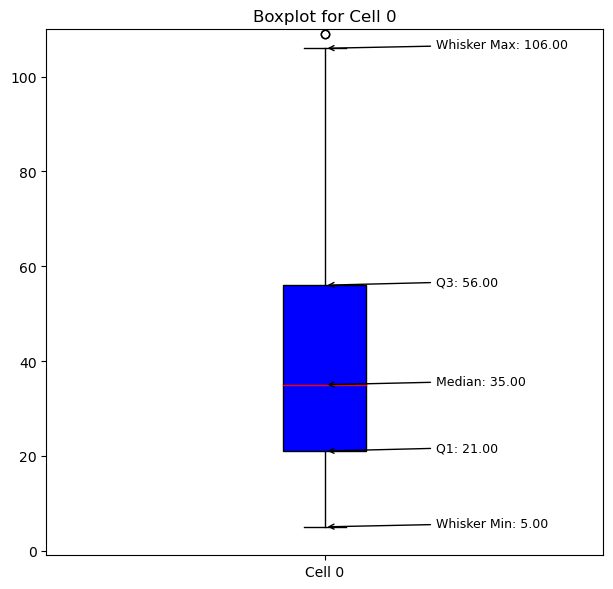

In [7]:
# Set the size of the figure
plt.figure(figsize=(12, 6))

# First subplot: boxplot for cell 0 values
plt.subplot(1, 2, 1)
bp = plt.boxplot(df_cell_0_filtered['Value'], vert=True, patch_artist=True, boxprops=dict(facecolor='blue'), medianprops=dict(color='red'))
plt.title('Boxplot for Cell 0')
plt.xticks([1], ['Cell 0'])
plt.ylim(-1, 110)

# Text coordinates for annotations
text_x = 1.2

# Annotate statistical values using arrows
plt.annotate(f'Whisker Min: {whisker_min:.2f}', xy=(1, whisker_min), xytext=(text_x, whisker_min),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Whisker Max: {whisker_max:.2f}', xy=(1, whisker_max), xytext=(text_x, whisker_max),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Q1: {q1:.2f}', xy=(1, q1), xytext=(text_x, q1),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Q3: {q3:.2f}', xy=(1, q3), xytext=(text_x, q3),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Median: {bp["medians"][0].get_ydata()[0]:.2f}', xy=(1, bp['medians'][0].get_ydata()[0]), xytext=(text_x, bp['medians'][0].get_ydata()[0]),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)

# Adjust the layout
plt.tight_layout()

# Show the plots
plt.show()

In [8]:
# Compute descriptive statistics
q1 = np.percentile(median_values['Value'], 25)
q3 = np.percentile(median_values['Value'], 75)
iqr = q3 - q1

In [9]:
# Calculate the min and max for the whiskers
whisker_min = np.min(median_values['Value'][median_values['Value'] >= q1 - 1.5 * iqr])
whisker_max = np.max(median_values['Value'][median_values['Value'] <= q3 + 1.5 * iqr])

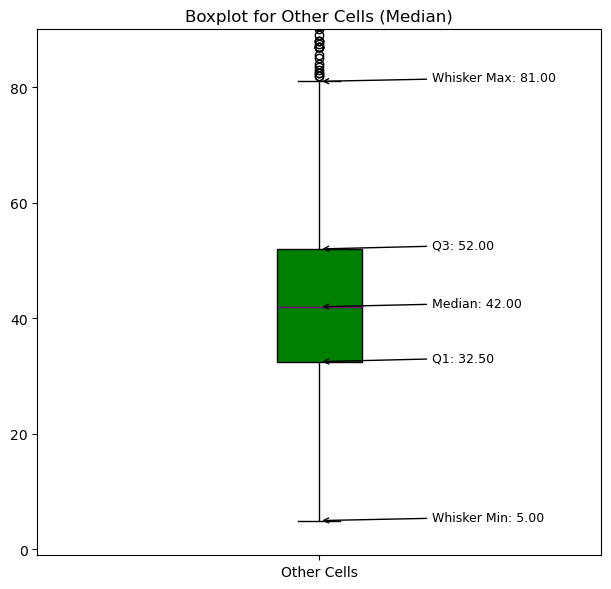

In [10]:
# Set the size of the figure
plt.figure(figsize=(12, 6))

# Second subplot: boxplot for median values of other cells
plt.subplot(1, 2, 2)
bp = plt.boxplot(median_values['Value'], vert=True, patch_artist=True, boxprops=dict(facecolor='green'), medianprops=dict(color='purple'))
plt.title('Boxplot for Other Cells (Median)')
plt.xticks([1], ['Other Cells'])
plt.ylim(-1, 90)

# Text coordinates for annotations
text_x = 1.2

# Annotate statistical values using arrows
plt.annotate(f'Whisker Min: {whisker_min:.2f}', xy=(1, whisker_min), xytext=(text_x, whisker_min),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Whisker Max: {whisker_max:.2f}', xy=(1, whisker_max), xytext=(text_x, whisker_max),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Q1: {q1:.2f}', xy=(1, q1), xytext=(text_x, q1),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Q3: {q3:.2f}', xy=(1, q3), xytext=(text_x, q3),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)
plt.annotate(f'Median: {bp["medians"][0].get_ydata()[0]:.2f}', xy=(1, bp['medians'][0].get_ydata()[0]), xytext=(text_x, bp['medians'][0].get_ydata()[0]),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=9)

# Adjust the layout
plt.tight_layout()

# Show the plots
plt.show()